In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

base_dir = '/content/drive/MyDrive/Dogtvt'

for split in ['train', 'valid', 'test']:
    path = os.path.join(base_dir, split)
    if os.path.exists(path):

        file_count = sum([len(files) for r, d, files in os.walk(path)])
        breed_count = len([d for d in os.listdir(path) if os.path.isdir(os.path.join(path, d))])

        print(f"{split.upper():<6} | Breeds: {breed_count:<4} | Total Images: {file_count}")

TRAIN  | Breeds: 119  | Total Images: 8330
VALID  | Breeds: 119  | Total Images: 2380
TEST   | Breeds: 119  | Total Images: 1190


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (299, 299)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

test_valid_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    os.path.join(base_dir, 'train'),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

valid_generator = test_valid_datagen.flow_from_directory(
    os.path.join(base_dir, 'valid'),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

test_generator = test_valid_datagen.flow_from_directory(
    os.path.join(base_dir, 'test'),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 8330 images belonging to 119 classes.
Found 2380 images belonging to 119 classes.
Found 1190 images belonging to 119 classes.


In [ ]:
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras import layers, models

base_model = InceptionV3(weights='imagenet', include_top=False, input_shape=(299, 299, 3))

base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(119, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("สร้างโมเดลสำเร็จแล้ว")

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
สร้างโมเดลสำเร็จแล้ว


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6)
checkpoint = ModelCheckpoint('best_dog_model.h5', monitor='val_accuracy', save_best_only=True)

history = model.fit(
    train_generator,
    epochs=20,
    validation_data=valid_generator,
    callbacks=[early_stop, reduce_lr, checkpoint]
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 13s/step - accuracy: 0.3028 - loss: 3.3622 

261/261 ━━━━━━━━━━━━━━━━━━━━ 4241s 16s/step - accuracy: 0.3035 - loss: 3.3581 - val_accuracy: 0.8328 - val_loss: 0.6159 - learning_rate: 0.0010
Epoch 2/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 881ms/step - accuracy: 0.6859 - loss: 1.1237

261/261 ━━━━━━━━━━━━━━━━━━━━ 245s 940ms/step - accuracy: 0.6859 - loss: 1.1237 - val_accuracy: 0.8424 - val_loss: 0.4850 - learning_rate: 0.0010
Epoch 3/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 880ms/step - accuracy: 0.7192 - loss: 0.9762

261/261 ━━━━━━━━━━━━━━━━━━━━ 245s 940ms/step - accuracy: 0.7192 - loss: 0.9762 - val_accuracy: 0.8592 - val_loss: 0.4420 - learning_rate: 0.0010
Epoch 4/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 248s 949ms/step - accuracy: 0.7345 - loss: 0.9121 - val_accuracy: 0.8584 - val_loss: 0.4483 - learning_rate: 0.0010
Epoch 5/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 898ms/step - accuracy: 0.7533 - loss: 0.8435

261/261 ━━━━━━━━━━━━━━━━━━━━ 249s 956ms/step - accuracy: 0.7532 - loss: 0.8437 - val_accuracy: 0.8613 - val_loss: 0.4493 - learning_rate: 0.0010
Epoch 6/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 893ms/step - accuracy: 0.7481 - loss: 0.8443

261/261 ━━━━━━━━━━━━━━━━━━━━ 248s 952ms/step - accuracy: 0.7481 - loss: 0.8443 - val_accuracy: 0.8660 - val_loss: 0.4199 - learning_rate: 0.0010
Epoch 7/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 246s 943ms/step - accuracy: 0.7549 - loss: 0.8362 - val_accuracy: 0.8563 - val_loss: 0.4380 - learning_rate: 0.0010
Epoch 8/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 247s 943ms/step - accuracy: 0.7553 - loss: 0.8268 - val_accuracy: 0.8605 - val_loss: 0.4214 - learning_rate: 0.0010
Epoch 9/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 882ms/step - accuracy: 0.7640 - loss: 0.7954

261/261 ━━━━━━━━━━━━━━━━━━━━ 246s 941ms/step - accuracy: 0.7640 - loss: 0.7954 - val_accuracy: 0.8710 - val_loss: 0.4095 - learning_rate: 0.0010
Epoch 10/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 244s 937ms/step - accuracy: 0.7526 - loss: 0.8038 - val_accuracy: 0.8639 - val_loss: 0.4362 - learning_rate: 0.0010
Epoch 11/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 248s 949ms/step - accuracy: 0.7613 - loss: 0.7801 - val_accuracy: 0.8639 - val_loss: 0.4245 - learning_rate: 0.0010
Epoch 12/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 246s 942ms/step - accuracy: 0.7624 - loss: 0.7661 - val_accuracy: 0.8660 - val_loss: 0.4205 - learning_rate: 0.0010
Epoch 13/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 874ms/step - accuracy: 0.7837 - loss: 0.6890

261/261 ━━━━━━━━━━━━━━━━━━━━ 244s 933ms/step - accuracy: 0.7837 - loss: 0.6889 - val_accuracy: 0.8748 - val_loss: 0.3885 - learning_rate: 2.0000e-04
Epoch 14/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 250s 957ms/step - accuracy: 0.8108 - loss: 0.6252 - val_accuracy: 0.8744 - val_loss: 0.3863 - learning_rate: 2.0000e-04
Epoch 15/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 888ms/step - accuracy: 0.8090 - loss: 0.5728

261/261 ━━━━━━━━━━━━━━━━━━━━ 247s 947ms/step - accuracy: 0.8090 - loss: 0.5729 - val_accuracy: 0.8836 - val_loss: 0.3780 - learning_rate: 2.0000e-04
Epoch 16/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 247s 946ms/step - accuracy: 0.8155 - loss: 0.5851 - val_accuracy: 0.8798 - val_loss: 0.3800 - learning_rate: 2.0000e-04
Epoch 17/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 890ms/step - accuracy: 0.8106 - loss: 0.6105

261/261 ━━━━━━━━━━━━━━━━━━━━ 253s 971ms/step - accuracy: 0.8106 - loss: 0.6105 - val_accuracy: 0.8853 - val_loss: 0.3714 - learning_rate: 2.0000e-04
Epoch 18/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 248s 949ms/step - accuracy: 0.8222 - loss: 0.5632 - val_accuracy: 0.8790 - val_loss: 0.3734 - learning_rate: 2.0000e-04
Epoch 19/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 242s 927ms/step - accuracy: 0.8289 - loss: 0.5358 - val_accuracy: 0.8815 - val_loss: 0.3762 - learning_rate: 2.0000e-04
Epoch 20/20
261/261 ━━━━━━━━━━━━━━━━━━━━ 247s 945ms/step - accuracy: 0.8222 - loss: 0.5625 - val_accuracy: 0.8819 - val_loss: 0.3721 - learning_rate: 2.0000e-04


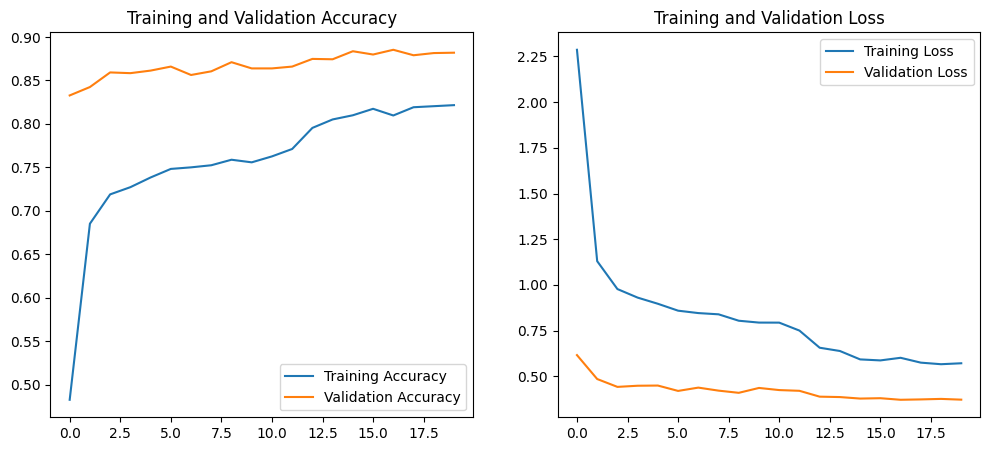

In [ ]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend(loc='lower right')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.legend(loc='upper right')

plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(test_generator)
print(f"\n✅ Test Accuracy: {test_acc * 100:.2f}%")

38/38 ━━━━━━━━━━━━━━━━━━━━ 448s 12s/step - accuracy: 0.8797 - loss: 0.3500

✅ Test Accuracy: 88.15%


In [ ]:
model.save('/content/drive/MyDrive/InceptionV3_Model.keras')
print("เซฟโมเดลเรียบร้อยแล้ว")

เซฟโมเดลเรียบร้อยแล้ว


In [ ]:
class_names = list(train_generator.class_indices.keys())

with open('dog_labels.txt', 'w') as f:
    for name in class_names:
        f.write(f"{name}\n")

print("สร้างไฟล์ dog_labels.txt สำเร็จแล้ว")

สร้างไฟล์ dog_labels.txt สำเร็จแล้ว


In [ ]:
import tensorflow as tf

model = tf.keras.models.load_model('/content/drive/MyDrive/Project73/InceptionV3_Model.keras')
print("โหลดโมเดลกลับมาเรียบร้อยแล้ว")

โหลดโมเดลกลับมาเรียบร้อยแล้ว


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 6 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


โหลดรายชื่อ 119 สายพันธุ์เรียบร้อย


Saving n02111889_1363_jpg.rf.15dea6c217b1c68ea614f301f351b91e.jpg to n02111889_1363_jpg.rf.15dea6c217b1c68ea614f301f351b91e.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step

ผลการทำนาย: Samoyed
ความมั่นใจ: 94.13%


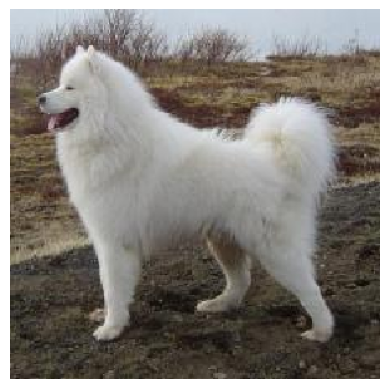

In [ ]:
import numpy as np
from google.colab import files
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import os

labels = []
label_path = '/content/drive/MyDrive/Project73/dog_labels.txt'

if os.path.exists(label_path):
    with open(label_path, 'r') as f:
        labels = [line.strip() for line in f.readlines()]
    print(f"โหลดรายชื่อ {len(labels)} สายพันธุ์เรียบร้อย")
else:
    drive_path = '/content/drive/MyDrive/Dogtvt/test/Samoyed/n02111889_1363_jpg.rf.15dea6c217b1c68ea614f301f351b91e.jpg'
    if os.path.exists(drive_path):
        with open(drive_path, 'r') as f:
            labels = [line.strip() for line in f.readlines()]
        print(f"โหลดรายชื่อจาก Drive เรียบร้อย")
    else:
        print("ไม่พบไฟล์")

if labels:
    uploaded = files.upload()

    for fn in uploaded.keys():
        img = image.load_img(fn, target_size=(299, 299))
        x = image.img_to_array(img) / 255.0
        x = np.expand_dims(x, axis=0)

        preds = model.predict(x)
        idx = np.argmax(preds[0])
        score = preds[0][idx] * 100

        print(f"\nผลการทำนาย: {labels[idx]}")
        print(f"ความมั่นใจ: {score:.2f}%")

        plt.imshow(img)
        plt.axis('off')
        plt.show()